# Lab 6 of 8 — Reinforcement learning

*Learn a policy by interacting, then save it.*

**Coverage.** Chapter 20.

**Goal.** Train tabular Q-learning, evaluate the greedy policy, visualize values/actions, and save the Q-table.

## Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np


def find_project_root(marker="all_datasets"):
    """Search the script/working folder and their parents for the project folder holding `marker`."""
    starts = [Path.cwd()]
    try:
        starts.insert(0, Path(__file__).resolve().parent)  # not defined inside a notebook
    except NameError:
        pass
    for start in starts:
        for folder in [start, *start.parents]:
            if (folder / marker).is_dir():
                return folder
    raise FileNotFoundError(f"Could not find a '{marker}' folder above {starts}")


# The PDF's `PROJECT_ROOT = Path.cwd().parent` only works for notebooks directly in all_experiments/;
# this finds the same project root from inside "ML Lab 6/".
PROJECT_ROOT = find_project_root()
MODELS = PROJECT_ROOT / "models"
MODELS.mkdir(exist_ok=True)

## Part A — Tabular Q-learning in a 4×4 GridWorld

A 4 × 4 grid: start top-left, goal bottom-right, and a trap. Ordinary moves cost −0.04, the goal pays +1, and the trap pays −1 and terminates. Walls leave the position unchanged. `step` returns the next state, the reward, and whether the episode terminated.

In [2]:
rng = np.random.default_rng(42)
ROWS, COLS = 4, 4
START, GOAL, TRAP = (0, 0), (3, 3), (1, 3)
ACTIONS = [(-1, 0), (1, 0), (0, -1), (0, 1)]  # up, down, left, right
ACTION_NAMES = ["up", "down", "left", "right"]
ARROWS = {"up": (0, 1), "down": (0, -1), "left": (-1, 0), "right": (1, 0)}


def step(state, action):
    """Apply one action. Returns (next_state, reward, done)."""
    r, c = state
    dr, dc = ACTIONS[action]
    next_state = (min(max(r + dr, 0), ROWS - 1), min(max(c + dc, 0), COLS - 1))
    if next_state == GOAL:
        return next_state, 1.0, True
    if next_state == TRAP:
        return next_state, -1.0, True
    return next_state, -0.04, False

Initialize state–action Q-values to zero. Update each toward *reward + discounted best next-state value*, with step size α and discount γ. Exploration decays from ε = 1.

In [3]:
Q = np.zeros((ROWS, COLS, len(ACTIONS)))
alpha, gamma = 0.15, 0.95
epsilon, min_epsilon = 1.0, 0.05


def choose_action(state, explore=True):
    if explore and rng.random() < epsilon:
        return int(rng.integers(len(ACTIONS)))  # explore: random move
    return int(np.argmax(Q[state]))  # exploit: best known move


training_returns = []
for episode in range(5000):
    state, episode_return = START, 0.0
    for _ in range(100):
        action = choose_action(state)
        next_state, reward, done = step(state, action)
        episode_return += reward
        target = reward if done else reward + gamma * np.max(Q[next_state])
        Q[state][action] += alpha * (target - Q[state][action])
        state = next_state
        if done:
            break
    training_returns.append(episode_return)
    epsilon = max(min_epsilon, epsilon * 0.9985)

print(f"final epsilon: {epsilon:.3f}")

final epsilon: 0.050


Plot returns smoothed over 100 episodes as exploration decays.

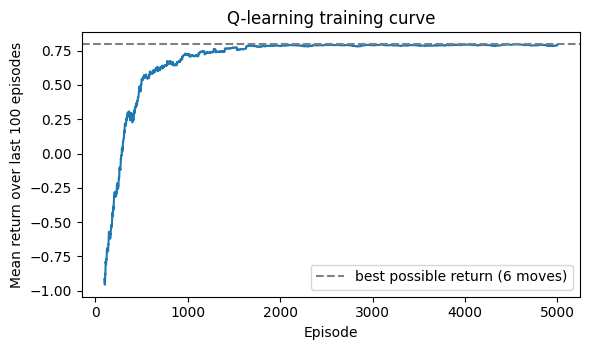

In [4]:
window = 100
moving = np.convolve(training_returns, np.ones(window) / window, mode="valid")
plt.figure(figsize=(6, 3.6))
plt.plot(np.arange(window - 1, len(training_returns)), moving)
plt.axhline(0.8, linestyle="--", color="grey", label="best possible return (6 moves)")
plt.xlabel("Episode")
plt.ylabel("Mean return over last 100 episodes")
plt.title("Q-learning training curve")
plt.legend()
plt.tight_layout()
plt.show()

Evaluate separately with exploration off, choosing the largest Q-value in each cell.

In [5]:
successes, returns = 0, []
for _ in range(200):
    state, total = START, 0.0
    for _ in range(100):
        state, reward, done = step(state, choose_action(state, explore=False))
        total += reward
        if done:
            successes += int(state == GOAL)
            break
    returns.append(total)
print("success rate:", successes / 200)
print("mean return:", round(float(np.mean(returns)), 3))
print("learned action at start:", ACTION_NAMES[choose_action(START, explore=False)])

success rate: 1.0
mean return: 0.8
learned action at start: down


**Inspect.** The six-move optimum is 5(−0.04) + 1 = 0.80, and the evaluated greedy policy reaches it: **success rate 1.0 and mean return 0.8 over 200 episodes run with exploration off**, with *down* as the first move. The training curve shows why the number is trustworthy. A random agent starts near −0.91 per episode (it stumbles into the trap or wanders paying −0.04 a step), climbs through 0.5 by about episode 500 and 0.7 by about episode 940, then flattens at 0.78–0.80 once ε hits its 0.05 floor (around episode 2,000). The curve sits a hair *below* 0.80 because training still takes a random move 5% of the time; the separate greedy evaluation removes that and lands exactly on 0.80.

## Part B — The Q-table is the model: save it and read the policy

Save the Q-table; deployment chooses each state's highest-valued action without retraining.

In [6]:
q_path = MODELS / "gridworld_q_table.npy"
np.save(q_path, Q)
Q_loaded = np.load(q_path)
assert np.array_equal(Q, Q_loaded)

policy = np.full((ROWS, COLS), "", dtype=object)
for r in range(ROWS):
    for c in range(COLS):
        policy[r, c] = "GOAL" if (r, c) == GOAL else "TRAP" if (r, c) == TRAP \
            else ACTION_NAMES[int(np.argmax(Q_loaded[r, c]))]
print(policy)

[['down' 'down' 'down' 'left']
 ['down' 'down' 'down' 'TRAP']
 ['right' 'down' 'down' 'down']
 ['right' 'right' 'right' 'GOAL']]


Plot greedy actions as arrows over maximum Q-values.

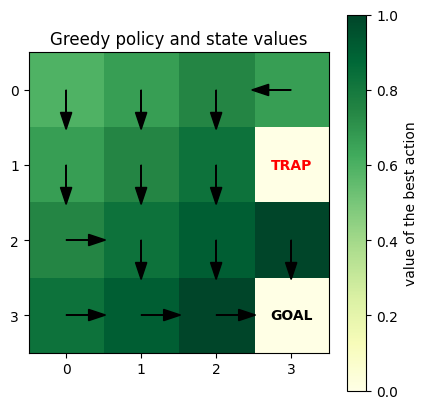

In [7]:
def plot_policy(Q_table, title, trap=TRAP, goal=GOAL):
    values = Q_table.max(axis=2)
    plt.figure(figsize=(4.4, 4.2))
    plt.imshow(values, cmap="YlGn")
    plt.colorbar(label="value of the best action")
    for r in range(ROWS):
        for c in range(COLS):
            if (r, c) == goal:
                plt.text(c, r, "GOAL", ha="center", va="center", fontweight="bold")
            elif (r, c) == trap:
                plt.text(c, r, "TRAP", ha="center", va="center", color="red", fontweight="bold")
            else:
                dx, dy = ARROWS[ACTION_NAMES[int(np.argmax(Q_table[r, c]))]]
                plt.arrow(c, r, 0.3 * dx, -0.3 * dy, head_width=0.15, color="black")
    plt.xticks(range(COLS))
    plt.yticks(range(ROWS))
    plt.title(title)
    plt.tight_layout()
    plt.show()


plot_policy(Q_loaded, "Greedy policy and state values")

In [8]:
# Supporting numbers for the inspection below: best-action value in every cell, and the greedy route.
print(np.round(Q_loaded.max(axis=2), 2))

state, route = START, [START]
for _ in range(20):
    state, _, done = step(state, int(np.argmax(Q_loaded[state])))
    route.append(state)
    if done:
        break
print("greedy route:", route)
print("moves:", len(route) - 1, " return:", round(-0.04 * (len(route) - 2) + 1.0, 2))

[[0.59 0.67 0.74 0.67]
 [0.67 0.74 0.82 0.  ]
 [0.74 0.82 0.91 1.  ]
 [0.82 0.91 1.   0.  ]]
greedy route: [(0, 0), (1, 0), (2, 0), (2, 1), (3, 1), (3, 2), (3, 3)]
moves: 6  return: 0.8


**Inspect.** The reloaded table (asserted identical to the trained one) gives this policy, with the greedy route from the start `(0,0) → (1,0) → (2,0) → (2,1) → (3,1) → (3,2) → (3,3)`: six moves, return 0.80.

```
down  down  down  left
down  down  down  TRAP
right down  down  down
right right right GOAL
```

- **Around the trap.** The trap is at row 1, column 3. The cell above it, `(0,3)`, points *left* rather than down, and the cell beside it, `(1,2)`, points *down* rather than right, so no learned action steps into the trap.
- **Values rise toward the goal.** Along the route the best-action value climbs 0.59 → 0.67 → 0.74 → 0.82 → 0.91 → 1.00. Each step back from the goal multiplies the value by γ = 0.95 and subtracts the 0.04 step cost, so neighbours differ by roughly 0.07–0.09. The start value is just the discounted return of the optimal route: 0.95⁵ − 0.04(1 + 0.95 + 0.95² + 0.95³ + 0.95⁴) ≈ 0.59.
- **Terminal cells show 0.** `GOAL` and `TRAP` end the episode, so no action is ever taken from them and their Q-values stay at the initial zero. The heat map therefore looks pale there even though the goal is the best place to be: the reward is collected on the *transition into* it, which is the 1.00 in its neighbours.
- **Ties.** Many six-move routes are equally good (any path of three downs and three rights that avoids the trap). Which one the greedy policy follows is decided by tiny differences in how often each was updated, so the route can change with the seed or exploration schedule while the return (0.80) does not.

## Try it yourself

Change the step cost, trap, exploration schedule, or discount. Predict the policy change, retrain, and check with `plot_policy`.

**Predictions.**
**Expectations.** The reward structure suggests what each change should do (reasoned from the rewards, then checked against the retrained policies below):

1. **Step cost −0.5.** Every move is far more expensive, but the trap (−1) is still worse than the six-move route to the goal (5 × −0.5 + 1 = −1.5, against −2.5 for the shortest route into the trap), so the *route should not change*; only the returns and values get much lower.
2. **Trap moved to (2,2), next to the goal.** The old route's middle cells now border the trap, so a safe policy should shift to the other side: along the top row and down the right column, the only way in that avoids `(2,2)`.
3. **Discount γ = 0.5.** Distant rewards are heavily discounted, so values shrink fast with distance, but the *ranking* of moves is unchanged, so the route should stay the same. The risk is that cells far from the goal end up with values near zero, where small differences are easy to lose.
4. **Faster exploration decay (0.99).** ε reaches its floor in about 300 episodes instead of 2,000, so the agent sees much less of the grid. It should still find a good route because the grid is tiny, but a *different* six-move route would not be surprising, and on a larger grid it could get stuck with a worse one.

In [9]:
def make_step(step_cost=-0.04, trap=TRAP):
    """Same dynamics as `step`, but with the step cost and trap location as parameters."""
    def variant_step(state, action):
        r, c = state
        dr, dc = ACTIONS[action]
        nxt = (min(max(r + dr, 0), ROWS - 1), min(max(c + dc, 0), COLS - 1))
        if nxt == GOAL:
            return nxt, 1.0, True
        if nxt == trap:
            return nxt, -1.0, True
        return nxt, step_cost, False
    return variant_step


def train(step_cost=-0.04, trap=TRAP, gamma=0.95, decay=0.9985, episodes=5000, seed=42):
    """Re-run the lab's Q-learning with one or more settings changed. Returns the Q-table."""
    local_rng = np.random.default_rng(seed)
    local_step = make_step(step_cost, trap)
    table = np.zeros((ROWS, COLS, len(ACTIONS)))
    eps = 1.0
    for _ in range(episodes):
        state = START
        for _ in range(100):
            if local_rng.random() < eps:
                action = int(local_rng.integers(len(ACTIONS)))
            else:
                action = int(np.argmax(table[state]))
            nxt, reward, done = local_step(state, action)
            target = reward if done else reward + gamma * np.max(table[nxt])
            table[state][action] += alpha * (target - table[state][action])
            state = nxt
            if done:
                break
        eps = max(min_epsilon, eps * decay)
    return table


def greedy_route(table, step_cost=-0.04, trap=TRAP, limit=20):
    """Follow the greedy policy from START. Returns (route, total reward, ended in GOAL?)."""
    local_step = make_step(step_cost, trap)
    state, route, total = START, [START], 0.0
    for _ in range(limit):
        state, reward, done = local_step(state, int(np.argmax(table[state])))
        route.append(state)
        total += reward
        if done:
            break
    return route, round(total, 2), state == GOAL

In [10]:
experiments = {
    "baseline (cost -0.04, trap (1,3), gamma 0.95)": dict(),
    "harsher step cost -0.5": dict(step_cost=-0.5),
    "trap moved to (2,2), beside the goal": dict(trap=(2, 2)),
    "myopic discount gamma = 0.5": dict(gamma=0.5),
    "fast decay 0.99 (little exploration)": dict(decay=0.99),
}
tables = {}
for name, kwargs in experiments.items():
    tables[name] = train(**kwargs)
    route, total, reached = greedy_route(
        tables[name], step_cost=kwargs.get("step_cost", -0.04), trap=kwargs.get("trap", TRAP))
    print(f"{name}\n   route={route}\n   return={total}, reaches goal={reached}, "
          f"start value={tables[name][START].max():.3f}")

baseline (cost -0.04, trap (1,3), gamma 0.95)
   route=[(0, 0), (1, 0), (2, 0), (2, 1), (3, 1), (3, 2), (3, 3)]
   return=0.8, reaches goal=True, start value=0.593


harsher step cost -0.5
   route=[(0, 0), (1, 0), (2, 0), (2, 1), (3, 1), (3, 2), (3, 3)]
   return=-1.5, reaches goal=True, start value=-1.488


trap moved to (2,2), beside the goal
   route=[(0, 0), (0, 1), (0, 2), (0, 3), (1, 3), (2, 3), (3, 3)]
   return=0.8, reaches goal=True, start value=0.593


myopic discount gamma = 0.5
   route=[(0, 0), (1, 0), (2, 0), (2, 1), (3, 1), (3, 2), (3, 3)]
   return=0.8, reaches goal=True, start value=-0.046


fast decay 0.99 (little exploration)
   route=[(0, 0), (1, 0), (1, 1), (1, 2), (2, 2), (3, 2), (3, 3)]
   return=0.8, reaches goal=True, start value=0.593


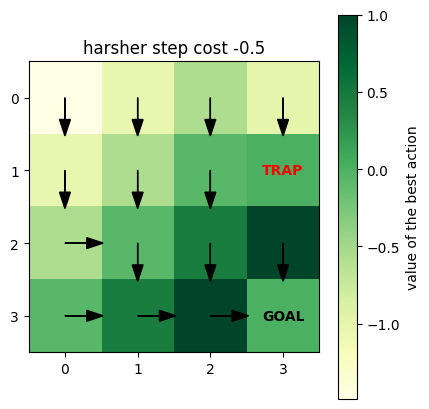

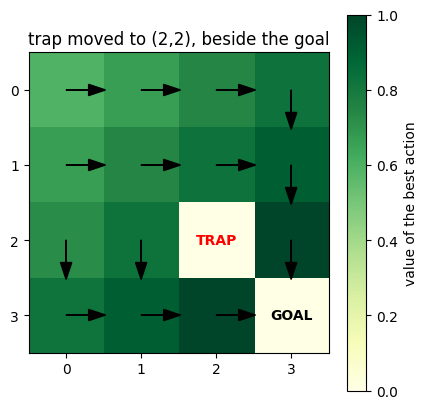

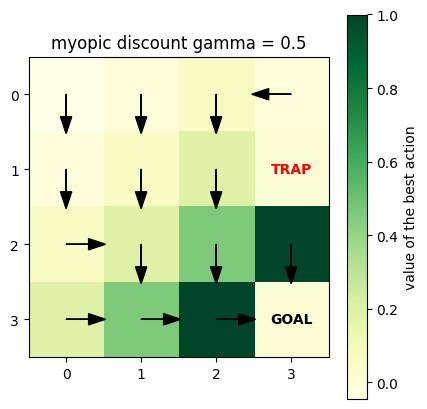

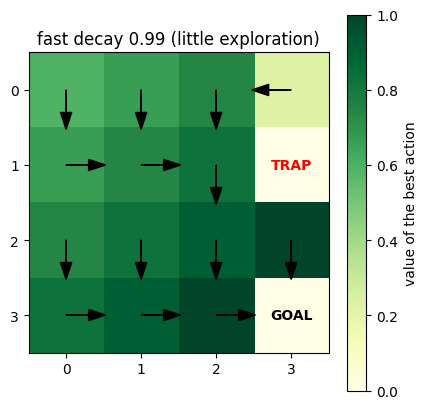

In [11]:
for name, kwargs in list(experiments.items())[1:]:
    plot_policy(tables[name], name, trap=kwargs.get("trap", TRAP))

**Result.**

| Change | Greedy route from the start | Return |
|---|---|---|
| Baseline (−0.04, trap `(1,3)`, γ = 0.95) | down, down, right, down, right, right | 0.80 |
| Step cost −0.5 | same route as baseline | −1.50 |
| Trap moved to `(2,2)` | right, right, right, down, down, down (top row, then the right column) | 0.80 |
| γ = 0.5 | same route as baseline | 0.80 |
| Decay 0.99 | down, right, right, down, down, right (a different six-move route) | 0.80 |

Each expectation held. The most instructive case is the moved trap: the policy that was optimal a moment ago would now walk next to the trap, and retraining reroutes around it with no change to the algorithm; only the environment's rewards differ. With the harsher step cost the policy is unchanged but the return drops to −1.5, which shows that the *value* of a policy can change a lot while the *policy itself* stays the same. A step cost large enough to make the trap cheaper than walking to the goal would flip the behaviour; −0.5 is not that large here. The γ = 0.5 case finds the same route from much smaller Q-values (see the start value printed above), so it has far less margin against noise on a bigger problem.

All of these use one seed (42), so route details such as the decay-0.99 path are one draw among several equally good six-move routes; the returns are the robust part.

## Verification checklist

- [x] The greedy policy reaches the goal in six moves, for a return of 0.80 (evaluation cell and the printed greedy route in Part B).
- [x] The evaluated success rate is reported over 200 episodes run without exploration (`explore=False`): 1.0.
- [x] `models/gridworld_q_table.npy` is saved, and the policy is read from the reloaded table (`Q_loaded`, asserted identical to `Q`).
- [x] The printed policy routes towards the goal and around the trap: the cell above the trap points left, the cell beside it points down.

## Check your understanding

**1. What are the state, action, reward, and transition in a reinforcement-learning formulation?**
- **State**: what the agent knows about the situation right now; here the grid cell `(row, col)`.
- **Action**: a choice the agent can make in a state; here up, down, left or right.
- **Reward**: the scalar feedback after an action; here −0.04 per ordinary move, +1 at the goal, −1 at the trap.
- **Transition**: the rule that produces the next state (and reward) from the current state and action; here the `step` function, where a move into a wall leaves the position unchanged. The agent does not need to know this rule in advance: Q-learning learns from sampled transitions.

**2. What two pieces of information appear in the tabular Q-learning backup value?**
The immediate **reward** received and the **discounted value of the best action in the next state**, `reward + γ · max Q(next_state)`. The Q-value is nudged toward this target by the step size α. At a terminal transition there is no next state, so the target is just the reward (the `if done` branch).

**3. Why should the exploratory training policy be evaluated separately from the final greedy policy?**
During training the agent deliberately takes random moves (ε-greedy), so its training returns mix what it has learned with the cost of exploring; the curve here tops out at about 0.79, not 0.80, because of the 5% random moves. The policy that will actually be deployed is the greedy one, so it must be measured on its own with exploration off, over fresh episodes. Here that gave a success rate of 1.0 and a return of exactly 0.80, which the noisy training curve alone could not confirm.